# Random Forest on TF-IDF

This notebook trains a Random Forest on the same TF-IDF features and train/test split as the Logistic Regression baseline. A forest of 200 deep trees can't be read directly, so we explain it with post-hoc methods.

The steps: global importance (grouped PFI, TreeSHAP) → feature effects (ALE) → heterogeneity (ICE, centered ICE) → individual decisions (SP-LIME, LIME, SHAP). Grouped PFI and ALE are used instead of plain PFI and PDP because several top terms are correlated (Section 8).

## 1. Setup

In [ ]:
import os, sys
if not os.path.exists("preprocessing.py"):                             
    os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..", "..")))  
sys.path.insert(0, os.getcwd())             

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score, accuracy_score
)
from sklearn.inspection import PartialDependenceDisplay

from lime.lime_text import LimeTextExplainer
import shap

from preprocessing import (
    preprocess_text, get_tfidf_features,
    get_train_test_split, select_top_k_terms, get_split_tfidf, RANDOM_STATE
)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv.gz")
df[["title", "text", "label", "label_encoded"]].head()

,title,text,label,label_encoded
0,BREAKING: GOP Chairman Grassley Has Had Enough...,"Donald Trump s White House is in chaos, and th...",fake,1
1,Failed GOP Candidates Remembered In Hilarious ...,Now that Donald Trump is the presumptive GOP n...,fake,1
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY ...,Mike Pence is a huge homophobe. He supports ex...,fake,1
3,California AG pledges to defend birth control ...,California Attorney General Xavier Becerra sai...,real,0
4,AZ RANCHERS Living On US-Mexico Border Destroy...,Twisted reasoning is all that comes from Pelos...,fake,1


## 3. Text Preprocessing

In [3]:
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
df[["full_text", "processed_text"]].head()

,full_text,processed_text
0,BREAKING: GOP Chairman Grassley Has Had Enough...,breaking gop chairman grassley enough demand t...
1,Failed GOP Candidates Remembered In Hilarious ...,failed gop candidate remembered hilarious mock...
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY ...,mike penny new dc neighbor hilariously trollin...
3,California AG pledges to defend birth control ...,california ag pledge defend birth control insu...
4,AZ RANCHERS Living On US-Mexico Border Destroy...,az rancher living u mexico border destroy nanc...


Quick check: compare one raw vs. processed example side by side.

In [4]:
print("RAW:\n", df["full_text"].iloc[0][:300])
print("\nPROCESSED:\n", df["processed_text"].iloc[0][:300])

RAW:
 BREAKING: GOP Chairman Grassley Has Had Enough, DEMANDS Trump Jr. Testimony Donald Trump s White House is in chaos, and they are trying to cover it up. Their Russia problems are mounting by the hour, and they refuse to acknowledge that there are problems surrounding all of this. To them, it s  fake 

PROCESSED:
 breaking gop chairman grassley enough demand trump jr testimony donald trump white house chaos trying cover russia problem mounting hour refuse acknowledge problem surrounding fake news hoax however fact bear thing differently seems crack congressional public leadership chuck grassley r iowa head se


## 4. TF-IDF Vectorization

In [5]:
X, y, tfidf = get_tfidf_features(df)

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (38633, 5000)


Same TF-IDF settings as the baseline (see its Section 4). This cell only shows the size of the matrix; the TF-IDF the model uses is fitted again in the next step, on the training articles only.

## 5. Train/Test Split

In [6]:
X_train, X_test, y_train, y_test, tfidf = get_split_tfidf(df)
feature_names = tfidf.get_feature_names_out()

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train shape: (30906, 5000)
Test shape: (7727, 5000)

Train class balance:
 label_encoded
0    0.549
1    0.451
Name: proportion, dtype: float64

Test class balance:
 label_encoded
0    0.548
1    0.452
Name: proportion, dtype: float64


## 6. Train Random Forest

A Random Forest trains 200 decision trees, each on a random sample of the training articles and choosing from a random subset of terms at every split, and then averages their votes. Because the trees differ, their mistakes partly cancel out, which makes the forest more stable than a single tree.

Tree depth and leaf size are capped to keep the forest smaller and much faster to explain with TreeSHAP.

In [7]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

## 7. Validate Predictive Performance

In [8]:
print(classification_report(y_test, y_pred, target_names=["real", "fake"]))

recall_fake = recall_score(y_test, y_pred, pos_label=1)
accuracy = accuracy_score(y_test, y_pred)
train_recall = recall_score(y_train, rf.predict(X_train), pos_label=1)

print(f"Fake-class recall (test):  {recall_fake:.4f}")
print(f"Fake-class recall (train): {train_recall:.4f}   <- large gap vs test = overfitting")
print(f"Accuracy (test): {accuracy:.4f}")

              precision    recall  f1-score   support

        real       0.95      0.99      0.97      4238
        fake       0.99      0.93      0.96      3489

    accuracy                           0.97      7727
   macro avg       0.97      0.96      0.97      7727
weighted avg       0.97      0.97      0.97      7727

Fake-class recall (test):  0.9347
Fake-class recall (train): 0.9623   <- large gap vs test = overfitting
Accuracy (test): 0.9662


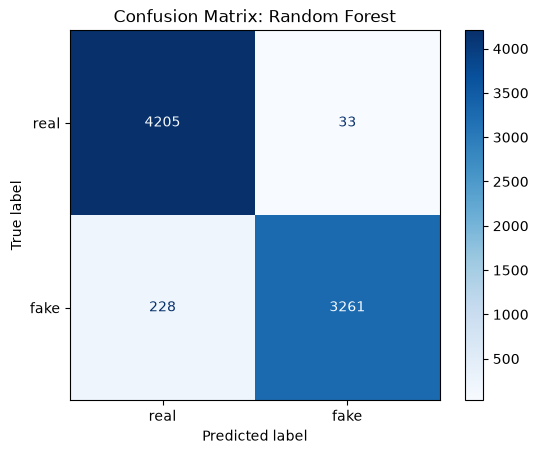

In [9]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["real", "fake"]).plot(cmap="Blues")
plt.title("Confusion Matrix: Random Forest")
plt.show()

- True Positive, correctly caught fake article: 3,261
- False Negative, fake article predicted as real: 228
- False Positive, real article predicted as fake: 33
- True Negative, correctly identified real article: 4,205

The forest catches 93.5% of fake articles (recall = 0.9347), and 99.0% of its "fake" flags are right (precision = 0.990). Accuracy is 96.6%.

Compared with the baseline, it raises fewer false alarms (33 vs 44) but misses more than twice as many fakes (228 vs 108), so both recall (0.935 vs 0.969) and accuracy (0.966 vs 0.980) are lower. It calls only 42.6% of test articles fake, below the real share of 45.2%, so it leans toward "real." For a reviewer who mostly worries about fakes slipping through, that's the wrong way to lean.

Training recall is 0.9623 against 0.9347 on test, so the forest fits its training data a bit better than new data, but the gap is small.

## 8. Top-K Terms and Multicollinearity Check

With 5,000 terms, looking at every term isn't practical: ALE and ICE would need thousands of plots, and a 5,000 × 5,000 correlation matrix can't be read. So we focus on the 30 terms most linked to the label (K = 30), ranked by chi-squared on the training data only.

Chi-squared measures how unevenly a term's weight is split between fake and real articles. Higher means a stronger link to the label, but it doesn't show the direction. We use it because it doesn't depend on any model, so every notebook shares the same list. TF-IDF weights aren't counts, so the scores are only used for ranking, not as significance tests.

In [10]:
K = 30
top_idx, top_terms, top_scores = select_top_k_terms(X_train, y_train, feature_names, k=K, method="chi2")
pd.DataFrame({"term": top_terms, "chi2_score": top_scores}).head(7)

,term,chi2_score
0,video,429.735134
1,said,354.357520
2,image,351.657391
3,via,273.043116
4,featured,245.148761
5,com,236.464647
6,hillary,229.692337


The top seven terms are video, said, image, via, featured, com and hillary. Five of them (video, image, via, featured, com) are source fingerprints: embedded videos, photo credits and links on fake sites. said is Reuters' writing style, and hillary is the partisan naming typical of fake sites. Before any model is involved, the label-linked terms are already dominated by fingerprints.

All 30 terms are used below, but tables and plots show only 7 at a time, since people can hold about 7 ± 2 items in working memory.

In [11]:
X_test_dense = X_test.toarray().astype(np.float32)

rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(X_test_dense.shape[0], size=500, replace=False)
X_sample = X_test_dense[sample_idx]          # 500-row sample for PDP/ICE and SHAP

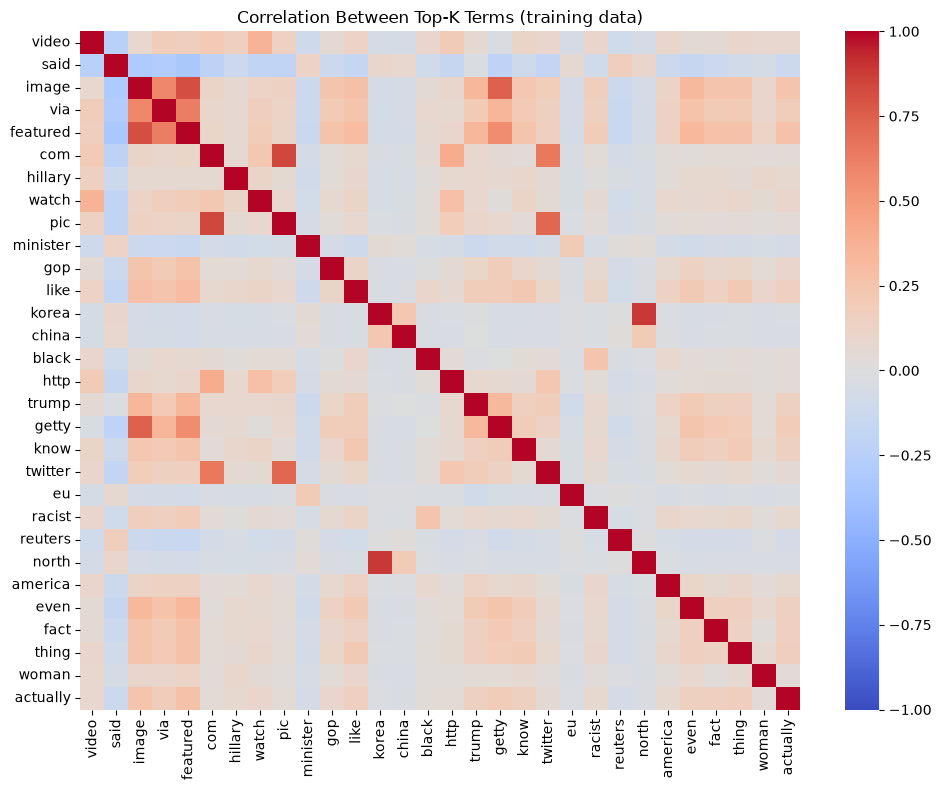

Pairs with |correlation| > 0.5:
korea     north       0.885267
com       pic         0.842176
image     featured    0.814060
          getty       0.743669
pic       twitter     0.721554
com       twitter     0.649922
via       featured    0.628802
image     via         0.579483
featured  getty       0.562061
dtype: float64


In [12]:
X_train_topk = pd.DataFrame(X_train[:, top_idx].toarray(), columns=top_terms)
corr = X_train_topk.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Between Top-K Terms (training data)")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high_pairs = pairs[pairs.abs() > 0.5]
if high_pairs.empty:
    print("No pairs of terms with |correlation| > 0.5")
else:
    print("Pairs with |correlation| > 0.5:")
    print(high_pairs.sort_values(key=abs, ascending=False))

Most cells are close to 0, but nine pairs go above 0.5, and they form three groups:

- **Photo credits:** image, featured, getty and via (0.56 to 0.81), all from "Featured image via Getty Images."
- **Links:** com, pic and twitter (0.65 to 0.84), from embedded tweets ("pic.twitter.com").
- **A name:** north and korea (0.89).

These words come as a package: an article that has one of them usually has the others. This rules out two explanation methods that assume the words are independent, plain PFI and PDP. We use grouped PFI (9.1) and ALE (10) instead, and ICE only uses terms outside these groups (11). Each section explains why. The check only covers the top 30 terms and linear relationships, so other dependencies may still exist.

## 9. Global Importance (PFI and TreeSHAP)

### 9.1 Grouped Permutation Feature Importance (PFI)

PFI shuffles a term's values across the test articles and measures how much Fake-class recall drops (averaged over 5 repeats). A big drop means the forest relies on that term to catch fakes.

**Why grouped and not plain PFI:** plain PFI shuffles one term at a time. If we shuffle only via, the article still has image, featured and getty, so the forest can still spot the photo credit and barely notices. Each term then looks unimportant, even though the photo credit as a whole matters a lot. Grouped PFI shuffles correlated terms together, with the same row order, so the whole group is removed at once. Terms that aren't correlated with anything are still shuffled on their own, so for them it's the same as plain PFI.

That turns the 30 top terms into 24 units: three groups (image, via, featured, getty; com, pic, twitter; korea, north) and 21 single terms.

In [13]:
def permutation_recall_drop(model, X_dense, y_true, groups, n_repeats=5, seed=RANDOM_STATE):
    """Shuffle each group of terms TOGETHER (same row order). A group is either a single term
    or a set of correlated terms, so correlated terms cannot stand in for each other."""
    rng = np.random.RandomState(seed)
    base = recall_score(y_true, model.predict(X_dense), pos_label=1)
    rows = []
    for terms in groups:
        cols = [tfidf.vocabulary_[t] for t in terms]
        original = X_dense[:, cols].copy()
        drops = []
        for _ in range(n_repeats):
            X_dense[:, cols] = original[rng.permutation(len(original))]
            drops.append(base - recall_score(y_true, model.predict(X_dense), pos_label=1))
        X_dense[:, cols] = original
        rows.append((", ".join(terms), np.mean(drops), np.std(drops)))
    result = pd.DataFrame(rows, columns=["term", "mean_recall_drop", "std"])
    return base, result.sort_values("mean_recall_drop", ascending=False)

# Merge the correlated pairs from Section 8 into groups (image-featured + image-getty -> one group)
term_groups = []
for a, b in high_pairs.index:
    linked = [g for g in term_groups if a in g or b in g]
    merged = {a, b}.union(*linked)
    term_groups = [g for g in term_groups if g not in linked] + [merged]

# Each correlated group is shuffled as one unit; every other top term on its own
pfi_groups = []
for t in top_terms:
    group = next((g for g in term_groups if t in g), {t})
    terms = [u for u in top_terms if u in group]          # keep chi-squared order
    if terms not in pfi_groups:
        pfi_groups.append(terms)

print(f"{len(top_terms)} top terms -> {len(pfi_groups)} PFI units")
base_recall, pfi_df = permutation_recall_drop(rf, X_test_dense, y_test, pfi_groups)
print(f"Recall before shuffling: {base_recall:.4f}")
pfi_df.head(7)

30 top terms -> 24 PFI units
Recall before shuffling: 0.9347


,term,mean_recall_drop,std
1,said,0.024076,0.001671
2,"image, via, featured, getty",0.018630,0.001175
0,video,0.008656,0.001488
17,reuters,0.006019,0.000924
6,minister,0.003611,0.000739
7,gop,0.001089,0.000493
18,america,0.000860,0.000906


said matters most: shuffling it drops recall by 0.024, about 84 of the 3,489 fake test articles. The photo-credit group comes a close second at 0.019 (about 65 articles). Then video (0.009, about 30), reuters (0.006, about 21) and minister (0.004, about 13). gop and america barely register, and america's standard deviation is as large as its drop.

The top two are different kinds of signal. said is Reuters' writing style, while the photo-credit group is just part of the fake sites' page layout. The forest leans on that layout almost as much as on its most important style word.

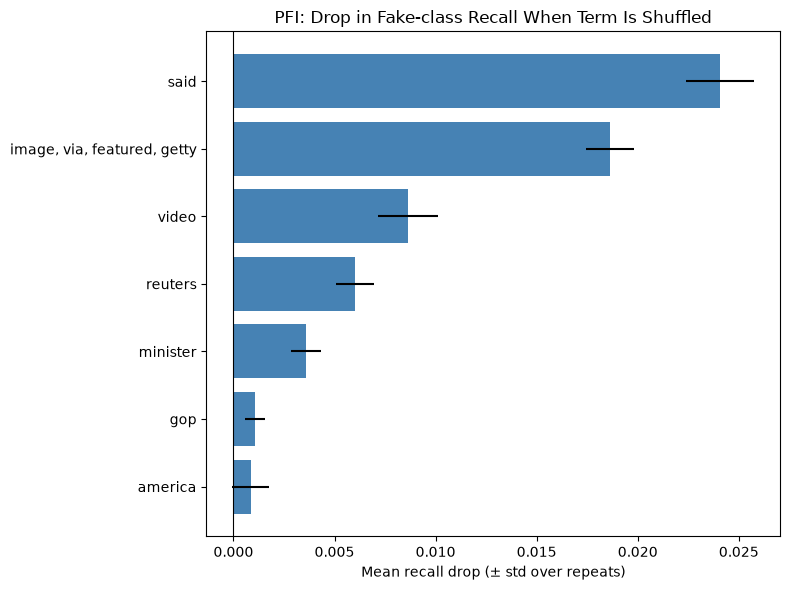

In [14]:
top_pfi = pfi_df.head(7).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top_pfi["term"], top_pfi["mean_recall_drop"], xerr=top_pfi["std"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("PFI: Drop in Fake-class Recall When Term Is Shuffled")
plt.xlabel("Mean recall drop (± std over repeats)")
plt.tight_layout()
plt.show()

said and the photo-credit group stand well apart from the rest, with narrow error bars. video, reuters and minister are smaller but clearly above zero. america's error bar reaches zero, so its effect can't be told apart from noise. The check below tests the rest against chance.

In [16]:
# Null check: shuffle 30 random terms outside the top-30, one at a time
rng_null = np.random.RandomState(RANDOM_STATE)
other_idx = rng_null.choice(np.setdiff1d(np.arange(len(feature_names)), top_idx), 30, replace=False)
_, pfi_null = permutation_recall_drop(rf, X_test_dense, y_test, [[feature_names[i]] for i in other_idx])
print(pfi_null["mean_recall_drop"].describe())

count    30.000000
mean     -0.000019
std       0.000132
min      -0.000688
25%       0.000000
50%       0.000000
75%       0.000000
max       0.000172
Name: mean_recall_drop, dtype: float64


As a check, we shuffled 30 random terms from outside the top 30, one at a time. Their median drop is exactly zero and the largest is 0.0002, less than one article (one article is 0.0003). Every top unit except america drops recall by more than that, so those effects are real.

### 9.2 TreeSHAP (global view)

SHAP splits each prediction into a contribution from each term. Starting from the forest's average predicted probability of fake, the contributions add up to the probability it gives that article. TreeSHAP calculates these values exactly for tree models.

With 200 deep trees this is slow, so the values are computed for a random sample of 200 test articles, the same sample as in the other notebooks, and then averaged.

In [17]:
explainer_shap = shap.TreeExplainer(rf)
X_shap = X_sample[:200]

sv = explainer_shap.shap_values(X_shap, check_additivity=False)

# SHAP's output format differs by version; extract values for the FAKE class (index 1)
if isinstance(sv, list):
    sv_fake = sv[1]
elif sv.ndim == 3:
    sv_fake = sv[:, :, 1]
else:
    sv_fake = sv

ev = explainer_shap.expected_value
base_value = ev[1] if np.ndim(ev) > 0 else ev
print("SHAP values shape:", sv_fake.shape)

SHAP values shape: (200, 5000)


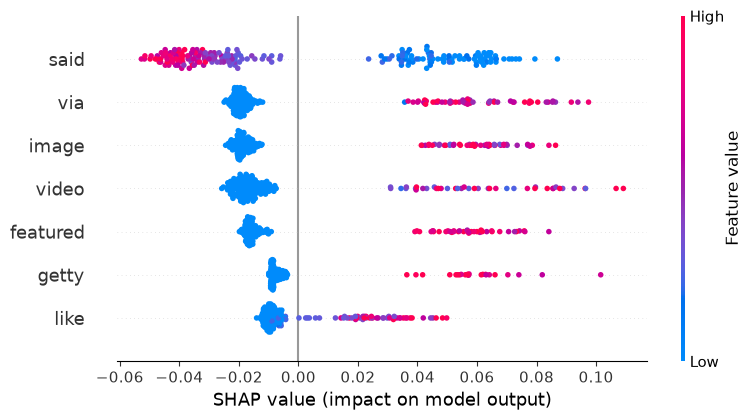

In [18]:
shap.summary_plot(sv_fake, X_shap, feature_names=list(feature_names), max_display=7)

In [19]:
shap_importance = pd.DataFrame({
    "term": feature_names,
    "mean_abs_shap": np.abs(sv_fake).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

shap_importance.head(7)

,term,mean_abs_shap
3905,said,0.040153
4789,via,0.030601
2206,image,0.028661
4793,video,0.026432
1705,featured,0.024424
1916,getty,0.013546
2626,like,0.013410


Each dot is one article: its position shows how much a term moved the probability of fake, and its color shows the term's weight (red high, blue low or absent).

Five of the top seven are photo-credit words or video: via, image, featured, getty and video. When an article contains one, it gets pushed toward fake by about 0.04 to 0.10. like also pushes toward fake when present. said goes the other way: articles that use it a lot are pushed toward real (up to about −0.05), and articles without it are pushed toward fake (up to about +0.08).

No single term dominates. said, the top term, moves the probability by only 0.040 on average.

SHAP ranks the photo-credit words one by one (via second, image third), while PFI only shows them as a group. That's the correlation at work: SHAP splits the credit for the photo credit between its words, while grouped PFI measures the group as a whole. Both say the photo credit is the second-biggest signal after said.

## 10. Feature Effects (ALE)

ALE shows how the predicted probability of fake changes as one term's weight goes up, so it shows the direction and size of each term's effect.

**Why ALE and not PDP:** PDP sets a term to each value in every article while leaving the rest of the article alone. For correlated terms that creates articles that can't exist, such as a photo credit with "image" but no "featured" or "getty", and the curve then describes those fake articles instead of real ones. ALE avoids this. It cuts the term's weights into small intervals and, in each interval, only uses the articles whose weight is actually in that interval. It measures how the prediction changes across that small step, then adds the steps up. 0 on the y-axis means the average prediction.

We plot the six top chi-squared terms: video, said, image, via, featured and com. Most articles don't contain a given term, so the first interval runs from 0 (absent) to the smallest weight at which the term shows up.

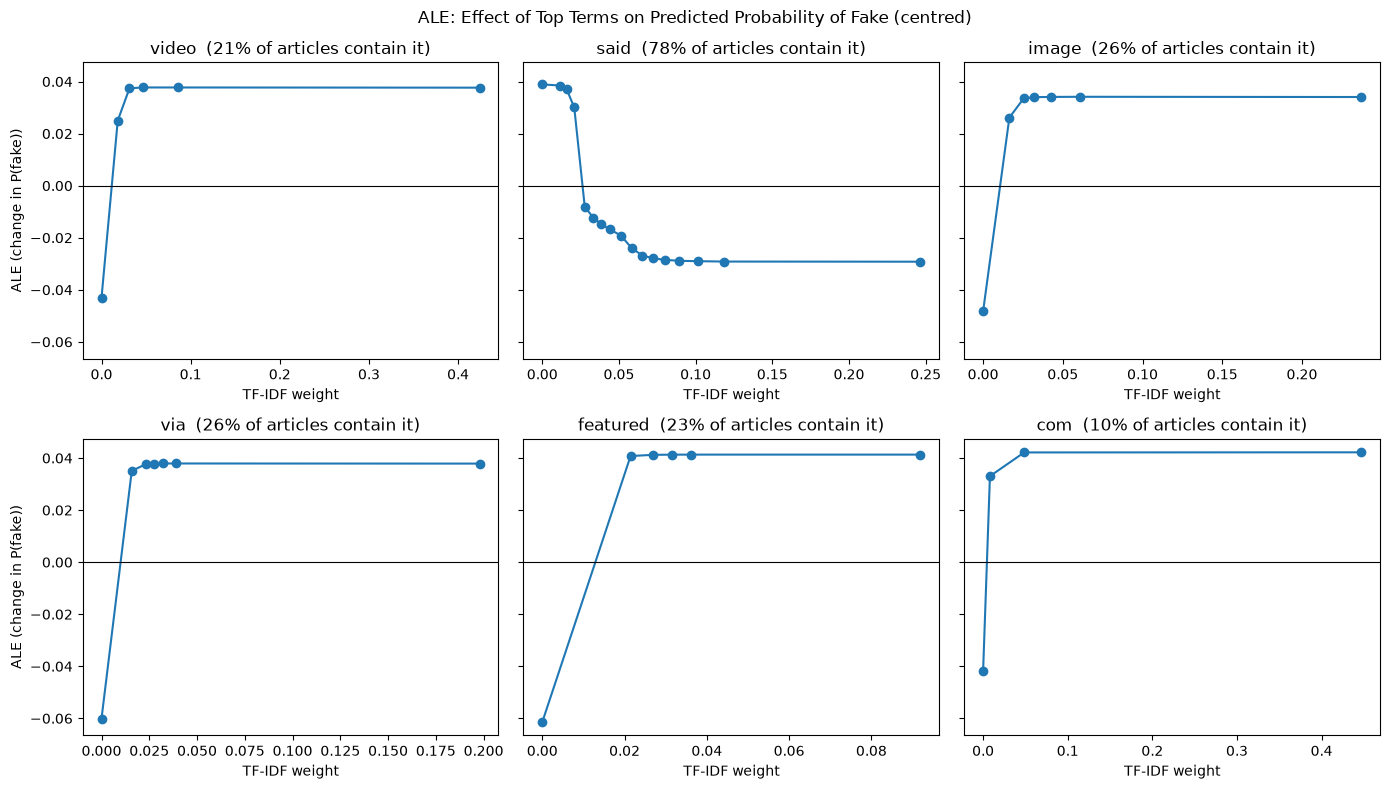

In [20]:
def ale_1d(predict, X, col, n_bins=20):
    """First-order ALE for one column. Bins are quantiles of the column, so most of the
    mass at weight 0 collapses into one edge. Returns bin edges and centred ALE values."""
    x = X[:, col]
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1)))
    if len(edges) < 2:
        return edges, np.zeros(len(edges))
    # article in interval (edges[k-1], edges[k]] -> bin k; articles exactly at the lowest edge go to bin 1
    bin_idx = np.clip(np.searchsorted(edges, x, side="left"), 1, len(edges) - 1)
    effects = np.zeros(len(edges) - 1)
    counts = np.zeros(len(edges) - 1)
    for k in range(1, len(edges)):
        rows = X[bin_idx == k]
        if len(rows) == 0:
            continue
        lo, hi = rows.copy(), rows.copy()
        lo[:, col], hi[:, col] = edges[k - 1], edges[k]
        effects[k - 1] = (predict(hi) - predict(lo)).mean()   # local effect, using only articles in this bin
        counts[k - 1] = len(rows)
    ale = np.concatenate([[0.0], np.cumsum(effects)])         # accumulate the local effects
    mids = (ale[:-1] + ale[1:]) / 2
    ale -= (mids * counts).sum() / counts.sum()               # centre so the average effect is 0
    return edges, ale

ale_terms = list(top_terms[:6])
predict_fake = lambda X: rf.predict_proba(X)[:, 1]

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey=True)
for ax, term in zip(axes.ravel(), ale_terms):
    col = tfidf.vocabulary_[term]
    edges, ale = ale_1d(predict_fake, X_test_dense, col)
    ax.plot(edges, ale, marker="o")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{term}  ({(X_test_dense[:, col] > 0).mean():.0%} of articles contain it)")
    ax.set_xlabel("TF-IDF weight")
for ax in axes[:, 0]:
    ax.set_ylabel("ALE (change in P(fake))")
fig.suptitle("ALE: Effect of Top Terms on Predicted Probability of Fake (centred)")
plt.tight_layout()
plt.show()

Five of the six curves look the same: a sharp jump from absent to present, then flat. For these terms, what matters is whether the word is there, not how often. The jumps are big for single words: via and featured move the prediction by about 10 points, and image, com and video by about 8.

said is different. It stays above zero at low weights, then drops between about 0.02 and 0.06 and ends about 3 points below average, a total change of about 7 points. One mention of said barely matters; articles that use it a lot, the way wire reports attribute every quote, get pushed toward real.

The directions match SHAP and the baseline. Five of the six terms (video, image, via, featured, com) are fingerprints, and each moves the prediction about as much as said.

## 11. Heterogeneity (ICE)

ICE draws one line per article instead of only the average, to show whether a term affects every article the same way.

ICE works like PDP, one article at a time, so it has the same problem with correlated terms, and there is no ALE version of it. So ICE only uses the top terms that aren't in any correlated group: video, said, hillary, watch, minister and gop.

ICE terms: ['video', 'said', 'hillary', 'watch', 'minister', 'gop']


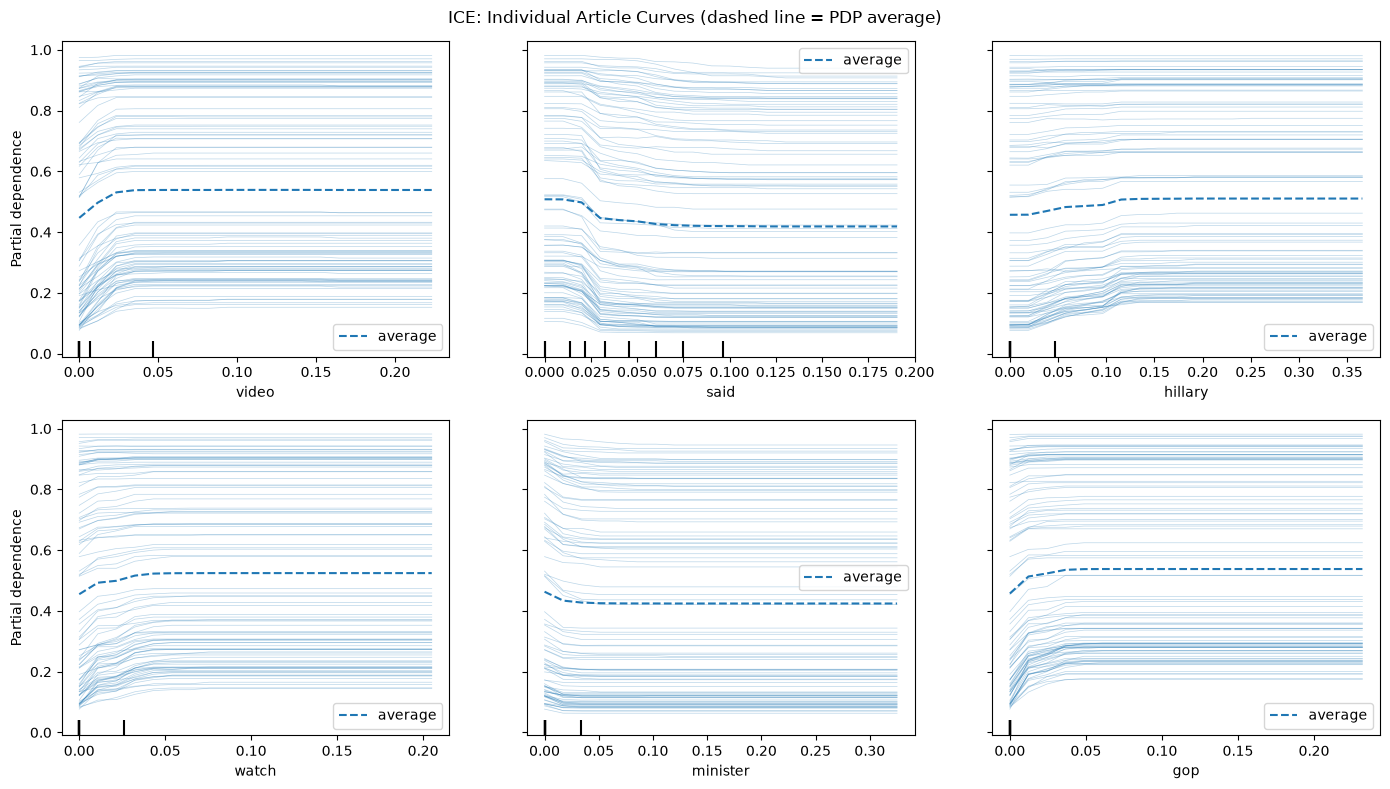

In [21]:
correlated_terms = {t for g in term_groups for t in g}
ice_idx = [i for i in top_idx if feature_names[i] not in correlated_terms][:6]
print("ICE terms:", list(feature_names[ice_idx]))

ice_display = PartialDependenceDisplay.from_estimator(
    rf, X_sample,
    features=ice_idx,
    feature_names=list(feature_names),
    kind="both",
    subsample=100,
    grid_resolution=20,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
ice_display.figure_.set_size_inches(14, 8)
ice_display.figure_.suptitle("ICE: Individual Article Curves (dashed line = PDP average)")
plt.tight_layout()
plt.show()

Each thin line is one of 100 articles, and the dashed line is the average. The lines start anywhere from about 0.08 to 0.98, because most of each prediction comes from the article's other words.

When a term goes from absent to present, nearly every line moves the same way as the average, but by very different amounts. The centered plot below makes this easier to see.

### 11.1 Centered ICE

The ICE plot can be misleading. Each line starts at a different height, set by the article's other words, so a line that starts high and moves a little looks the same as one that starts low and moves a lot. That makes it hard to compare how much the term actually changes each article.

Centered ICE fixes this by shifting every line to start at 0. Each line then shows only the change in predicted probability when the term is added to that article, so the size of the effect can be compared directly across articles.

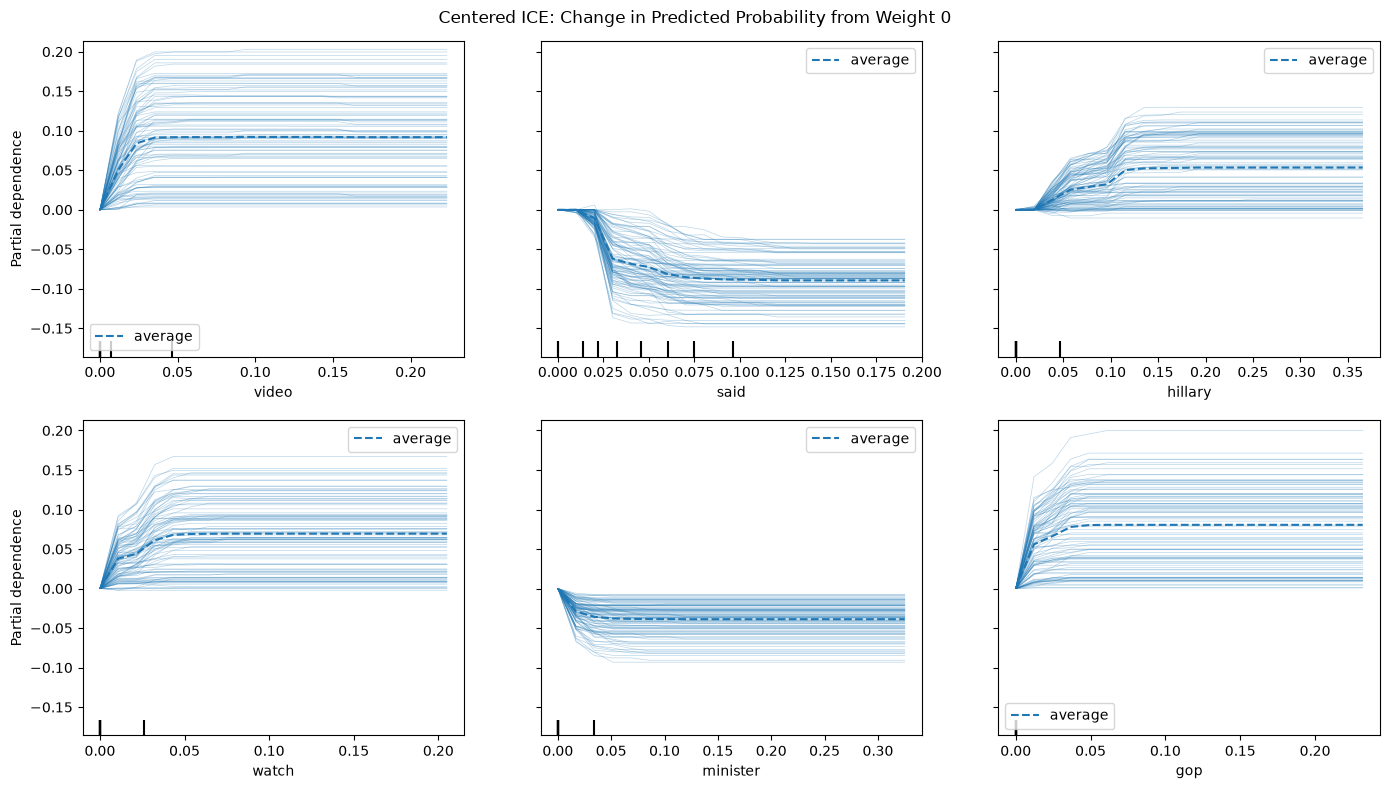

In [22]:
cice_display = PartialDependenceDisplay.from_estimator(
    rf, X_sample,
    features=ice_idx,
    feature_names=list(feature_names),
    kind="both",
    centered=True,
    subsample=100,
    grid_resolution=20,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
cice_display.figure_.set_size_inches(14, 8)
cice_display.figure_.suptitle("Centered ICE: Change in Predicted Probability from Weight 0")
plt.tight_layout()
plt.show()

In each panel, the lines go one way. Adding video raises every article's probability of fake, by anything from almost nothing to 20 points (about 9 on average). gop and watch also go up, by up to 20 and 16 points. said lowers every article, by up to 14 points (about 9 on average), and minister by up to 9. hillary goes up for almost every article, by up to 13 points, with a few dipping just below zero.

So each term's direction is consistent across articles, but its size isn't. The same word can move one article by 20 points and another by almost nothing, depending on what else the article contains.

## 12. Individual Decisions (LIME and SHAP)

So far we have looked at what drives the forest overall. Now we look at single articles. First, SP-LIME picks a small set of representative articles. Then we look at three cases chosen by outcome: the fake article the forest was most confident about, the fake article it missed most clearly, and the real article it most confidently flagged as fake.

In [23]:
from IPython.display import display

explainer_lime = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)

def predict_proba_text(texts):
    return rf.predict_proba(tfidf.transform(texts))

test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
y_true_arr = y_test.reset_index(drop=True).to_numpy()
y_pred_arr = np.asarray(y_pred)
proba_fake = rf.predict_proba(X_test)[:, 1]

tp = np.where((y_true_arr == 1) & (y_pred_arr == 1))[0]
fn = np.where((y_true_arr == 1) & (y_pred_arr == 0))[0]
fp = np.where((y_true_arr == 0) & (y_pred_arr == 1))[0]

cases = {
    "True Positive (fake, caught)":      tp[np.argmax(proba_fake[tp])],
    "False Negative (fake, missed)":     fn[np.argmin(proba_fake[fn])],
    "False Positive (real, flagged)":    fp[np.argmax(proba_fake[fp])],
}

### 12.1 SP-LIME: Choosing Representative Articles

Instead of picking articles by hand, SP-LIME (submodular pick) explains 200 random test articles and picks the 5 whose explanations together cover the most words with the least repetition. It does not look at the label or subject, so we check those afterwards.

In [24]:
from lime.submodular_pick import SubmodularPick

N_CANDIDATES = 200
N_PICKS = 5

rng_sp = np.random.RandomState(RANDOM_STATE)
cand_idx = rng_sp.choice(len(test_text), size=N_CANDIDATES, replace=False)
cand_text = test_text.iloc[cand_idx].tolist()

sp = SubmodularPick(
    explainer_lime, cand_text, predict_proba_text,
    method="full",
    num_exps_desired=N_PICKS,
    num_features=7,
    num_samples=1000,
    top_labels=None         
)
sp_idx = cand_idx[sp.V]   

In [25]:
def outcome(i):
    t, p = int(y_true_arr[i]), int(y_pred_arr[i])
    return {(1, 1): "TP (fake, caught)", (1, 0): "FN (fake, missed)",
            (0, 1): "FP (real, flagged)", (0, 0): "TN (real, correct)"}[(t, p)]

sp_table = pd.DataFrame({
    "subject": [df.loc[y_test.index[i], "subject"] for i in sp_idx],
    "true_label": ["fake" if y_true_arr[i] == 1 else "real" for i in sp_idx],
    "P(fake)": [round(float(proba_fake[i]), 3) for i in sp_idx],
    "outcome": [outcome(i) for i in sp_idx],
})
display(sp_table)

words = lambda e: {w for w, _ in e.as_list(label=1)}
picked_words = set().union(*[words(e) for e in sp.sp_explanations])
all_words = set().union(*[words(e) for e in sp.explanations])
print(f"Words in the 5 picks: {len(picked_words)} | words across all {N_CANDIDATES} explanations: {len(all_words)}")

,subject,true_label,P(fake),outcome
0,News,fake,0.814,"TP (fake, caught)"
1,News,fake,0.809,"TP (fake, caught)"
2,politicsNews,real,0.224,"TN (real, correct)"
3,politicsNews,real,0.237,"TN (real, correct)"
4,politicsNews,real,0.216,"TN (real, correct)"


Words in the 5 picks: 30 | words across all 200 explanations: 183


The five picks are two fake articles and three real ones, and the forest gets all five right. The subject column just mirrors the label (see `dataset_eda.ipynb`) and is only there for reference. All five scores are well away from 0.5 (0.81 and 0.81 for the fakes, 0.22 to 0.24 for the real ones).

Their explanations use 30 different words, out of 183 across all 200 explanations, so they cover only a small part of what the forest uses.

SP-LIME pick 1 | P(fake) = 0.814


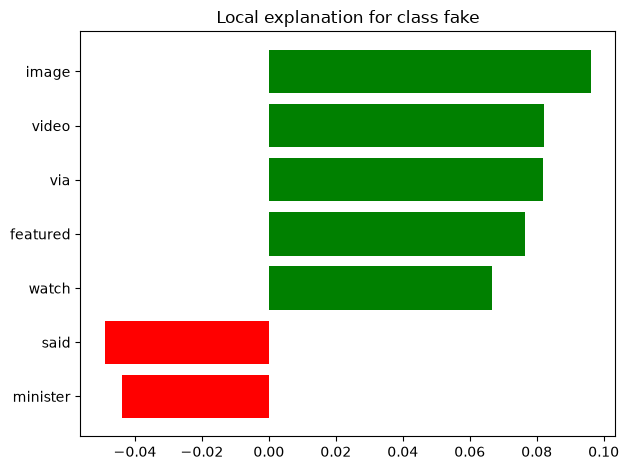

SP-LIME pick 2 | P(fake) = 0.809


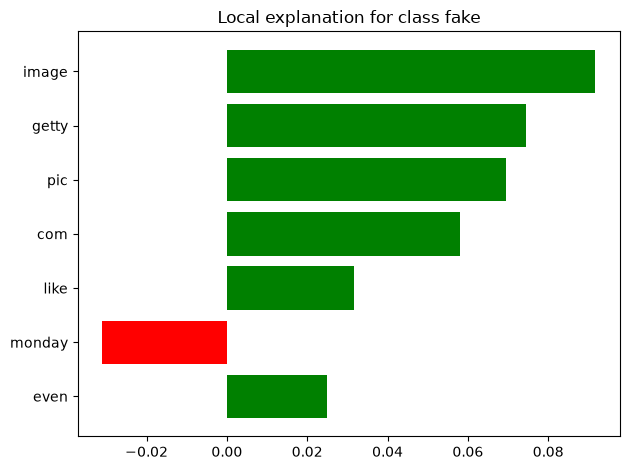

SP-LIME pick 3 | P(fake) = 0.224


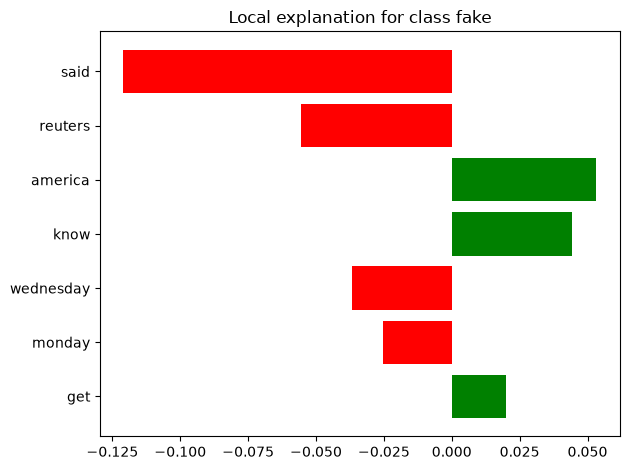

SP-LIME pick 4 | P(fake) = 0.237


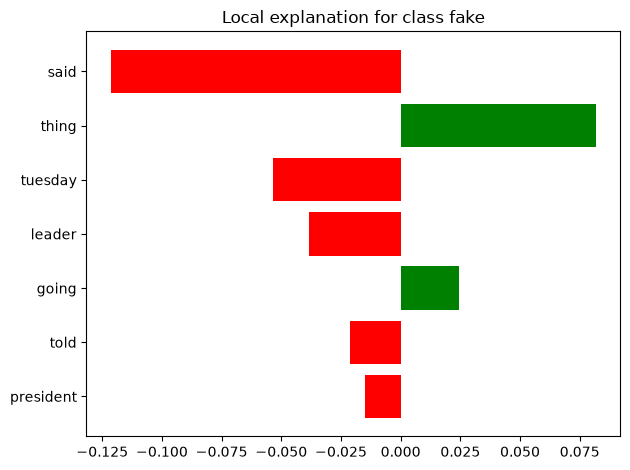

SP-LIME pick 5 | P(fake) = 0.216


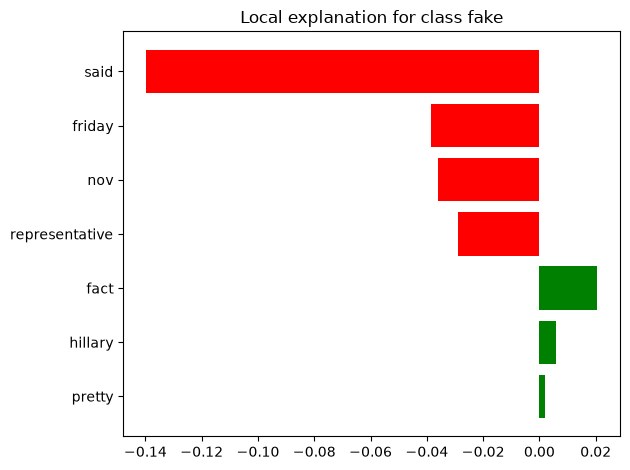

In [26]:
for rank, (exp, i) in enumerate(zip(sp.sp_explanations, sp_idx), start=1):
    print(f"SP-LIME pick {rank} | P(fake) = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

**Pick 1 (fake, 0.814).** image, video, via, featured and watch push toward fake (about 0.07 to 0.10 each), against said and minister (about 0.05 and 0.04). Almost all of the fake side is the photo credit and an embedded video.

**Pick 2 (fake, 0.809).** image and getty (the photo credit) plus pic and com (an embedded tweet) push toward fake, with like and even adding a little. Only monday pushes toward real.

**Pick 3 (real, 0.224).** said (−0.12) and reuters pull toward real, with wednesday and monday. america, know and get push the other way, but not enough.

**Pick 4 (real, 0.237).** said (−0.12) again does most of the work, with tuesday, leader, told and president. thing and going push toward fake.

**Pick 5 (real, 0.216).** said (−0.14) plus friday, nov and representative. fact and hillary push slightly toward fake.

The pattern is clear. The fake picks are decided by fingerprints (photo credits, tweet links), and the real picks by Reuters' style, above all said, plus weekdays and titles. Words that also appear in the global results point the same way here.

### 12.2 LIME: Three Cases by Outcome

LIME removes words from one article and watches how the predicted probability changes. Positive weights push toward fake, negative toward real.

True Positive (fake, caught) | P(fake) = 0.986


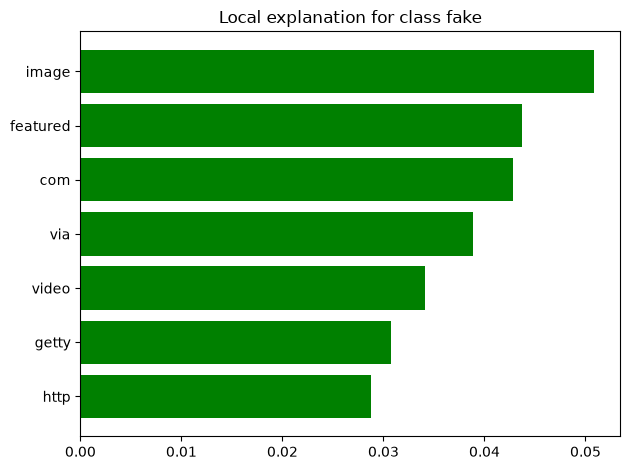

False Negative (fake, missed) | P(fake) = 0.114


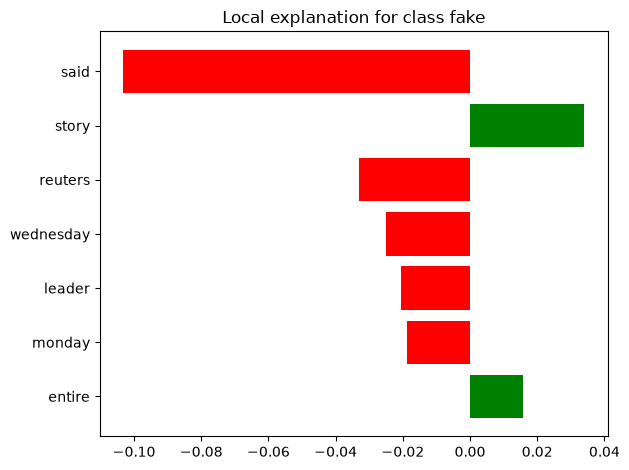

False Positive (real, flagged) | P(fake) = 0.670


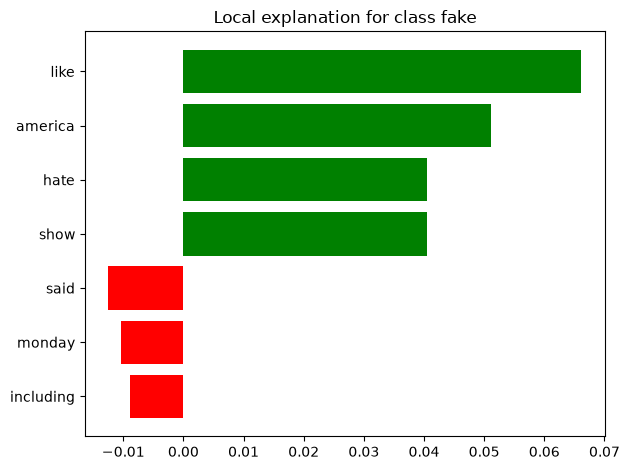

In [27]:
for name, i in cases.items():
    exp = explainer_lime.explain_instance(
        test_text.iloc[i], predict_proba_text,
        num_features=7, num_samples=1000, labels=(1,)
    )
    print(f"{name} | P(fake) = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

To see which articles these are, the cell below prints their headlines. The descriptions that follow refer to them.

In [30]:
for name, i in cases.items():
    print(name, "|", df.loc[y_test.index[i], "title"][:90])

True Positive (fake, caught) | Watch Confused Trump Wander Aimlessly Away From Limo (VIDEO)
False Negative (fake, missed) | N. KOREA’S LATEST MISSILE LAUNCH Aimed At Testing Carrying “Large Scale Heavy Nuclear Warh
False Positive (real, flagged) | Live from New York, it's a Trump-Clinton rematch - of sorts


These are the most extreme articles in each group.

**True Positive (P(fake) = 0.986).** The fake article ("Watch Confused Trump Wander Aimlessly Away From Limo (VIDEO)") is caught almost entirely on fingerprints and format words: image, featured, com, via, video, getty and http (about 0.03 to 0.05 each). The headline is obvious clickbait, but none of the seven words comes from what the article actually says.

**False Negative (P(fake) = 0.114).** This fake article ("N. KOREA'S LATEST MISSILE LAUNCH…") opens "North Korea said on Monday it had successfully conducted…", a wire report republished on a fake site. said (−0.10), reuters, wednesday, leader and monday pull toward real, and only story and entire push toward fake. It even mentions Reuters. It's labelled fake because of the site it came from, but the text is a news report, so the forest calls it real. That's a limit of the dataset as much as the model: labels describe the source, not each article.

**False Positive (P(fake) = 0.670).** This real article is about Alec Baldwin playing Trump on "Saturday Night Live." like, america, hate and show push toward fake (about 0.04 to 0.07), and said, monday and including pull only slightly toward real. A light Reuters entertainment piece uses casual words the forest links with fake sites.

The two errors show what the forest has really learned: what wire reports look like and what these fake sites look like. A fake site copying a wire report, or Reuters writing casually, is enough to fool it.

LIME uses random samples, so results change a little between runs, especially for the smaller words. Only the biggest bars should be read closely.

### 12.3 SHAP Waterfall (the missed fake article)

LIME approximates the forest around one article, while SHAP splits the forest's own prediction into exact contributions. Here SHAP explains the missed fake article from 12.2, so the two methods can be compared on the same case.

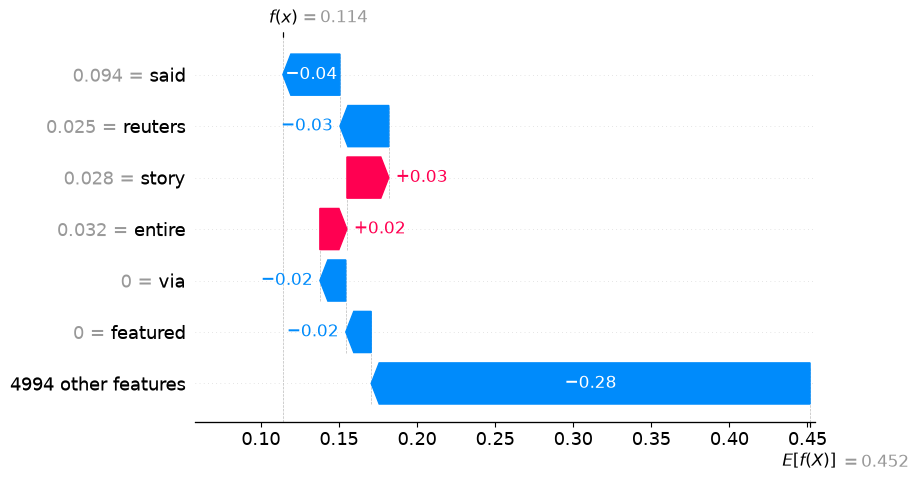

said       -0.0366
reuters    -0.0313
story       0.0268
entire      0.0173
via        -0.0166
featured   -0.0163
dtype: float64
All other terms combined: -0.2810
Base 0.452 + contributions = 0.114


In [28]:
fn_idx = cases["False Negative (fake, missed)"]
x_fn = X_test_dense[fn_idx:fn_idx + 1]

sv_fn = explainer_shap.shap_values(x_fn, check_additivity=False)
if isinstance(sv_fn, list):
    sv_fn_fake = sv_fn[1]
elif sv_fn.ndim == 3:
    sv_fn_fake = sv_fn[:, :, 1]
else:
    sv_fn_fake = sv_fn

shap.plots.waterfall(
    shap.Explanation(
        values=sv_fn_fake[0], base_values=base_value,
        data=x_fn[0], feature_names=list(feature_names)
    ),
    max_display=7
)

fn_contrib = pd.Series(sv_fn_fake[0], index=feature_names)
top6 = fn_contrib.reindex(fn_contrib.abs().sort_values(ascending=False).index).head(6)
print(top6.round(4))
print(f"All other terms combined: {fn_contrib.drop(top6.index).sum():.4f}")
print(f"Base {base_value:.3f} + contributions = {base_value + fn_contrib.sum():.3f}")

The waterfall starts at 0.452, the forest's average prediction, and ends at 0.114 for this missed fake. The printed check confirms the contributions add up exactly, which LIME doesn't guarantee.

said (−0.037) and reuters (−0.031) pull hardest toward real. story (+0.027) and entire (+0.017) are the only terms pushing toward fake. Then come via and featured (about −0.017 each): the article has neither, and SHAP shows that missing the photo credit also counts toward real. The other 4,994 terms add −0.281 together, about 83% of the net push, so the miss is mostly lots of small wire-report signals rather than a few big ones.

SHAP and LIME agree on the main words: said and reuters toward real, story and entire toward fake. SHAP adds what LIME can't show, that the missing photo-credit words also count against fake.

## 13. Summary

The Random Forest catches 93.5% of fake articles (recall 0.9347), with precision 0.990 and accuracy 0.966. It raises fewer false alarms than the baseline (33 vs 44) but misses more than twice as many fakes (228 vs 108), so on the project's main metric the extra complexity doesn't pay off. Training recall (0.962) is only a little above test recall, so it overfits slightly.

Several top terms come as packages (the photo credit, tweet links), so we used grouped PFI instead of plain PFI and ALE instead of PDP. The methods agree on what the forest relies on:

- **Grouped PFI:** said matters most (recall drop 0.024), with the photo-credit group close behind (0.019), then video, reuters and minister. All are well above random terms.
- **TreeSHAP:** five of the top seven terms are photo-credit words or video, and said pushes toward real when used often and toward fake when absent.
- **ALE:** a single fingerprint word moves the prediction by about 8 to 10 points, about as much as said.
- **ICE:** each term pushes every article the same way, but by anything from almost nothing to 20 points.
- **LIME:** the most confident fake call rests entirely on fingerprints. The worst errors are a wire report republished on a fake site and a casual Reuters entertainment piece.
- **SHAP waterfall:** for the missed fake, SHAP and LIME agree on said and reuters, and SHAP also shows that the missing photo credit counts against fake.

All methods agree on direction: video, the photo-credit words, gop, watch and hillary lean fake; said, reuters and minister lean real.

Overall, the forest has learned what Reuters articles and these fake sites look like, which works very well inside this dataset. Its errors show the limit: it judges an article by how it's written and laid out, not by whether what it says is true.